## 1. Konfigurasi proyek

In [5]:
import os
import subprocess
import sys
from pathlib import Path

# Cari root repository meskipun kernel notebook dimulai dari subfolder.
PROJECT_DIR = next(
    (path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
     if (path / "split.py").is_file() and (path / "2_balancing.py").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Tidak menemukan root proyek (split.py dan 2_balancing.py).")
os.chdir(PROJECT_DIR)

PYTHON = sys.executable
SOURCE_DIR = PROJECT_DIR / "Defect in NEU.v2i.yolov8"
DATA_DIR = PROJECT_DIR / "outputs" / "5_split" / "dataset_801010"
BALANCING_DIR = PROJECT_DIR / "outputs" / "2_balancing"
BALANCED_TRAIN_DIR = BALANCING_DIR / "train_balanced"
BALANCED_YAML = BALANCING_DIR / "data_balanced.yaml"
EDA_DIR = PROJECT_DIR / "outputs" / "1_eda"
TRAIN_DIR = PROJECT_DIR / "outputs" / "3_train"
EVALUATE_DIR = PROJECT_DIR / "outputs" / "4_evaluate"

MODEL = "yolov8n.pt"
EPOCHS = 100  # Kurangi, misalnya 5, untuk uji cepat.
IMGSZ = 640
BATCH = 16
PATIENCE = 20
USE_GPU = True  # Set False only if you intentionally want CPU training.

print("Project:", PROJECT_DIR)
print("Dataset:", DATA_DIR)
print("Python:", PYTHON)

Project: C:\Users\user\Downloads\NEUDefect
Dataset: C:\Users\user\Downloads\NEUDefect\outputs\5_split\dataset_801010
Python: c:\python314\python.exe


## 2. Dependensi

Jalankan sekali bila ada modul yang belum terpasang di kernel aktif.

In [6]:
%pip install -q ultralytics albumentations scikit-image scikit-learn pandas matplotlib pyyaml opencv-python ipykernel

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


## GPU lokal (NVIDIA)

Di VS Code, pilih kernel **Python (NEUDefect GPU)**. Kernel tersebut harus menggunakan `.venv` proyek. Jika membuat ulang environment, pasang PyTorch CUDA di terminal proyek:

```powershell
.venv\Scripts\python.exe -m pip install --index-url https://download.pytorch.org/whl/cu130 --extra-index-url https://pypi.org/simple torch==2.14.1+cu130 torchvision==0.29.1+cu130 ipykernel
.venv\Scripts\python.exe -m ipykernel install --user --name neudefect-gpu --display-name "Python (NEUDefect GPU)"
```

Setelah instalasi, restart kernel lalu pilih **Python (NEUDefect GPU)**. Sel berikut memeriksa PyTorch CUDA sebelum training; jika GPU tidak tersedia, sel akan berhenti dengan pesan yang jelas. `USE_GPU = False` dapat dipilih bila sengaja ingin menjalankan YOLO di CPU. KNN/SVM dan ekstraksi HOG tetap berjalan di CPU.

In [ ]:
import torch

if USE_GPU and not torch.cuda.is_available():
    raise RuntimeError(
        f"GPU CUDA tidak tersedia pada kernel {sys.executable}. "
        "Pilih kernel Python (NEUDefect GPU), restart kernel, lalu jalankan ulang. "
        "Periksa juga torch.cuda.is_available()."
    )

DEVICE = "0" if USE_GPU else "cpu"
print("PyTorch:", torch.__version__)
print("CUDA build:", torch.version.cuda)
print("Device training:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 1))


## 3. Siapkan split dataset

Dataset utama memakai split 80/10/10 dari `split.py`. Jika output split sudah tersedia, notebook menggunakannya tanpa membagi ulang.

In [8]:
if not (DATA_DIR / "data.yaml").is_file():
    if DATA_DIR.exists() and any(DATA_DIR.iterdir()):
        raise FileExistsError(
            f"Folder split sudah ada tetapi data.yaml tidak ditemukan: {DATA_DIR}. "
            "Periksa folder tersebut atau pilih output split yang bersih."
        )
    if not SOURCE_DIR.is_dir():
        raise FileNotFoundError(f"Dataset sumber tidak ditemukan: {SOURCE_DIR}")
    subprocess.run([PYTHON, str(PROJECT_DIR / "split.py")], cwd=PROJECT_DIR, check=True)

for split_name in ("train", "valid", "test"):
    for subfolder in ("images", "labels"):
        folder = DATA_DIR / split_name / subfolder
        if not folder.is_dir():
            raise FileNotFoundError(f"Folder dataset tidak ditemukan: {folder}")
print("Dataset siap:", DATA_DIR)

Dataset siap: C:\Users\user\Downloads\NEUDefect\outputs\5_split\dataset_801010


## 4. Exploratory Data Analysis

In [9]:
subprocess.run(
    [PYTHON, str(PROJECT_DIR / "1_eda.py"), "--data_dir", str(DATA_DIR), "--out_dir", str(EDA_DIR)],
    cwd=PROJECT_DIR,
    check=True,
)

CompletedProcess(args=['c:\\python314\\python.exe', 'C:\\Users\\user\\Downloads\\NEUDefect\\1_eda.py', '--data_dir', 'C:\\Users\\user\\Downloads\\NEUDefect\\outputs\\5_split\\dataset_801010', '--out_dir', 'C:\\Users\\user\\Downloads\\NEUDefect\\outputs\\1_eda'], returncode=0)

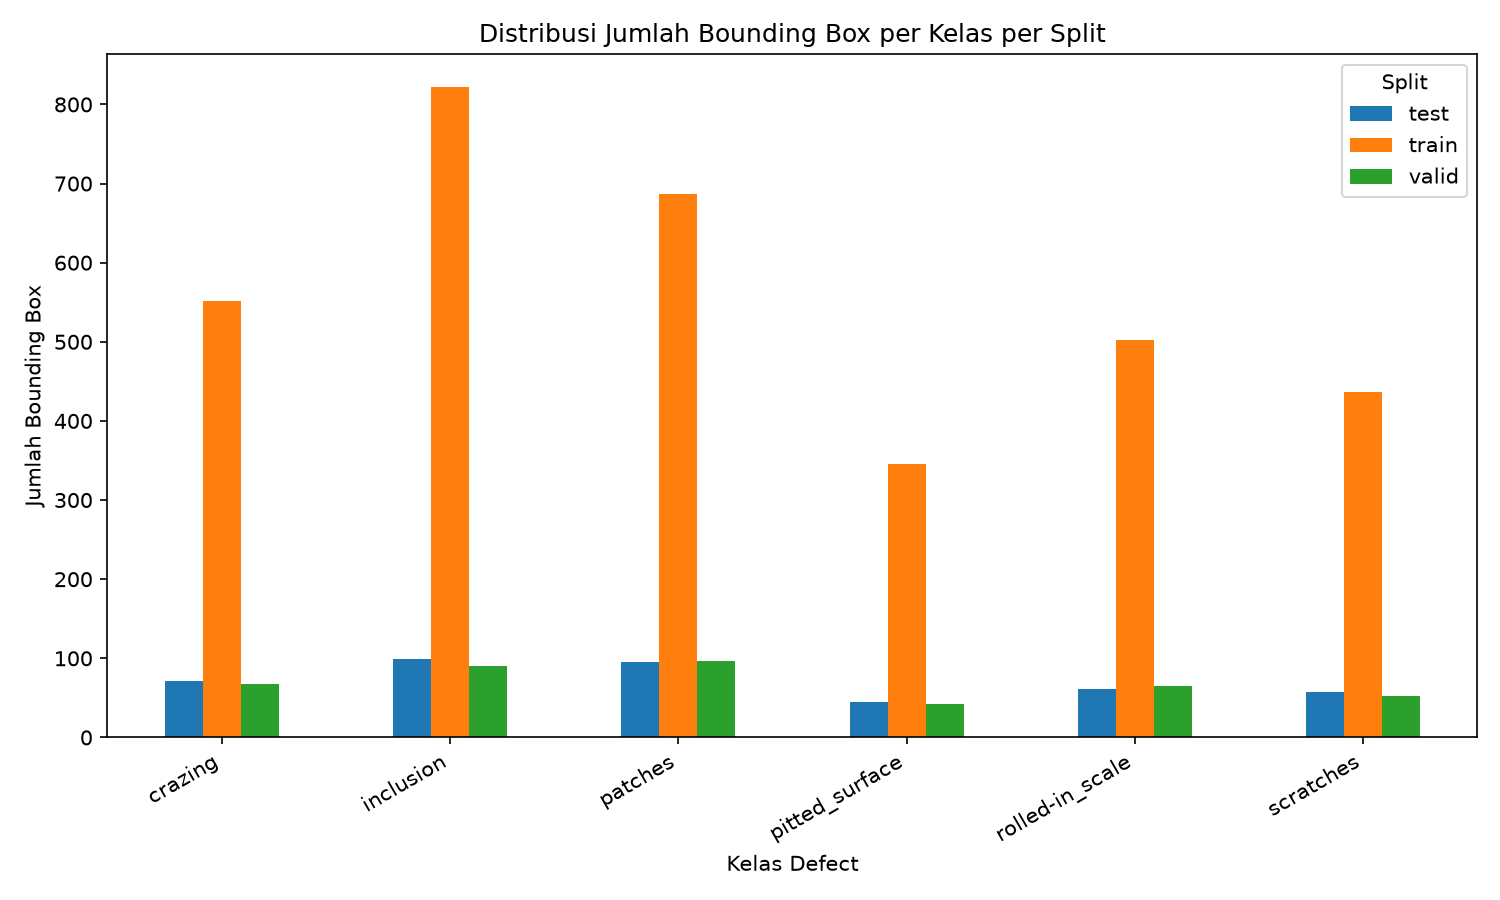

RINGKASAN EDA
Rasio split dataset:
  train: 1439 gambar (80.0%)
  valid: 180 gambar (10.0%)
  test: 180 gambar (10.0%)
  total: 1799 gambar

Kelas dengan box terbanyak di train: inclusion (822 box)
Kelas dengan box tersedikit di train: pitted_surface (345 box)
Rasio imbalance (max/min): 2.38x
Kesimpulan: Dataset TIDAK seimbang secara jumlah box per kelas, meskipun jumlah GAMBAR per kelas relatif seimbang.


In [10]:
from IPython.display import Image, display

display(Image(filename=str(EDA_DIR / "class_distribution.png")))
print((EDA_DIR / "summary.txt").read_text(encoding="utf-8"))

## 5. Balancing data train

Hanya train yang di-oversampling. Validasi dan test tetap menggunakan data asli. Sel ini membuat ulang folder balancing default setiap kali dijalankan.

In [11]:
subprocess.run(
    [
        PYTHON, str(PROJECT_DIR / "2_balancing.py"),
        "--data_dir", str(DATA_DIR),
        "--out_dir", str(BALANCED_TRAIN_DIR),
        "--overwrite",
    ],
    cwd=PROJECT_DIR,
    check=True,
)

CompletedProcess(args=['c:\\python314\\python.exe', 'C:\\Users\\user\\Downloads\\NEUDefect\\2_balancing.py', '--data_dir', 'C:\\Users\\user\\Downloads\\NEUDefect\\outputs\\5_split\\dataset_801010', '--out_dir', 'C:\\Users\\user\\Downloads\\NEUDefect\\outputs\\2_balancing\\train_balanced', '--overwrite'], returncode=0)

In [12]:
import pandas as pd

balancing_report = pd.read_csv(BALANCING_DIR / "balancing_report.csv")
display(balancing_report)
print("Balanced dataset YAML:", BALANCED_YAML)

,class_name,before,after
0,crazing,551,814
1,inclusion,822,871
2,patches,687,897
3,pitted_surface,345,845
4,rolled-in_scale,502,820
5,scratches,437,798


Balanced dataset YAML: C:\Users\user\Downloads\NEUDefect\outputs\2_balancing\data_balanced.yaml


## 6. Training YOLOv8

Melatih skenario unbalanced dan balanced dengan konfigurasi yang sama. Hasil training, evaluasi validasi/test, dan tabel perbandingan disimpan di `outputs/3_train/`.

In [ ]:
subprocess.run(
    [
        PYTHON, str(PROJECT_DIR / "3_train.py"),
        "--data_dir", str(DATA_DIR),
        "--balanced_data", str(BALANCED_YAML),
        "--out_dir", str(TRAIN_DIR),
        "--model", MODEL,
        "--epochs", str(EPOCHS),
        "--imgsz", str(IMGSZ),
        "--batch", str(BATCH),
        "--patience", str(PATIENCE),
        "--device", str(DEVICE),
    ],
    cwd=PROJECT_DIR,
    check=True,
)

### Ringkasan training

In [ ]:
from IPython.display import Image, display

comparison_path = TRAIN_DIR / "experiment_comparison.csv"
if not comparison_path.is_file():
    raise FileNotFoundError(f"Ringkasan training tidak ditemukan: {comparison_path}")
experiment_comparison = pd.read_csv(comparison_path)
display(experiment_comparison)

for _, row in experiment_comparison.iterrows():
    run_dir = Path(row["run_dir"])
    print(row["scenario"], "->", run_dir)
    for image_name in ("results.png", "confusion_matrix_normalized.png"):
        image_path = run_dir / image_name
        if image_path.is_file():
            display(Image(filename=str(image_path)))

## 7. Evaluasi detail dan visualisasi

Jalankan evaluasi tambahan untuk model-model yang berhasil dilatih. Hasil disimpan terpisah di `outputs/4_evaluate/`.

In [ ]:
for _, row in experiment_comparison.iterrows():
    run_dir = Path(row["run_dir"])
    weights = run_dir / "weights" / "best.pt"
    if not weights.is_file():
        raise FileNotFoundError(f"Bobot terbaik tidak ditemukan: {weights}")
    subprocess.run(
        [
            PYTHON, str(PROJECT_DIR / "4_evaluate_and_visualize.py"),
            "--weights", str(weights),
            "--data_dir", str(DATA_DIR),
            "--split", "test",
            "--out_dir", str(EVALUATE_DIR),
        ],
        cwd=PROJECT_DIR,
        check=True,
    )

In [ ]:
for _, row in experiment_comparison.iterrows():
    run_dir = Path(row["run_dir"])
    eval_run = EVALUATE_DIR / f"{run_dir.name}_test"
    grid = eval_run / "prediction_grid_test.png"
    print(row["scenario"])
    if grid.is_file():
        display(Image(filename=str(grid)))
    else:
        print("Grid belum ditemukan:", grid)

## 8. Baseline klasifikasi crop: KNN dan SVM

KNN/SVM mengklasifikasikan crop dari bounding box ground truth; keduanya bukan detektor objek. Skrip menggunakan dataset default `outputs/5_split/dataset_801010` dan mencetak classification report serta confusion matrix.

In [ ]:
expected_classical_data = PROJECT_DIR / "outputs" / "5_split" / "dataset_801010"
if DATA_DIR.resolve() != expected_classical_data.resolve():
    raise ValueError(f"KNN/SVM saat ini menggunakan dataset default: {expected_classical_data}")
subprocess.run([PYTHON, str(PROJECT_DIR / "KNN.py")], cwd=PROJECT_DIR, check=True)

In [ ]:
subprocess.run([PYTHON, str(PROJECT_DIR / "SVM.py")], cwd=PROJECT_DIR, check=True)